ML: Programe permettant d'apprendre des relations à partir de données pour effectuer des prédictions ou prendre des décisions.

# prédire la souscription d'un produit bancaire

Une banque réalise des campagnes de prospection téléphonique.

Elle souhaite mieux cibler ses campagnes afin de consacrer davantage de temps aux clients susceptibles de souscrire un dépôt à terme.

https://archive.ics.uci.edu/dataset/222/bank+marketing


DONC: L'objectif est de comprendre les données avant de construire un modèle de classification qui prédit si un client va souscrire (yes) ou non (no) à un dépôt à terme.



Acceder à no données sur drive:

- https://inside-machinelearning.com/charger-fichiers-depuis-un-drive-public-sur-google-colab/

- https://medium.com/@simonprdhm/2-mani%C3%A8res-simple-de-charger-un-fichier-csv-dans-google-colab-3b86616d248a



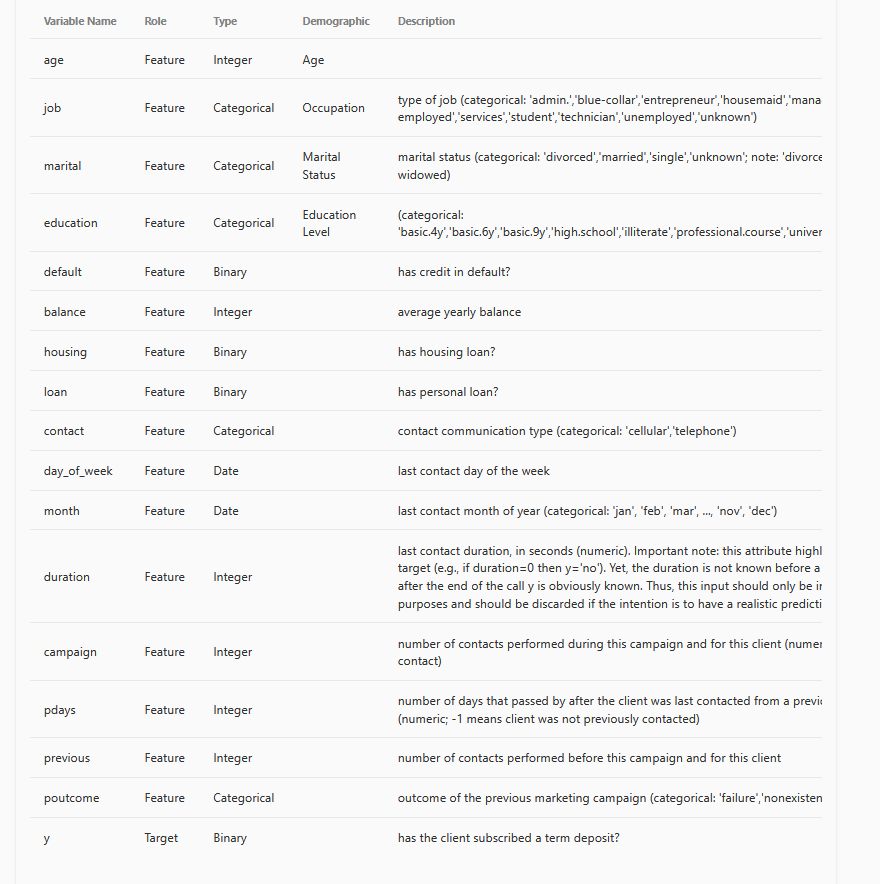

Installation de dépenance de téléchargement de données

%pip install gdown

In [4]:
#from google.colab import drive
#drive.mount('/content/drive')

# Une fois le Drive monté, vous pourrez accéder à votre dossier via :
# /content/drive/My Drive/Colab Notebooks/data/tab/

In [5]:

import gdown
import os

# Lien de partage du dossier Google Drive
folder_url = 'https://drive.google.com/drive/folders/1xWsjHmxq0wlsVqF_60ih8_cPAXNY302j?usp=sharing'

# Dossier de destination local
output_dir = 'donnees_drive'

# Téléchargement du dossier complet
gdown.download_folder(url=folder_url, output=output_dir, quiet=False, use_cookies=False)

# Afficher les fichiers téléchargés
if os.path.exists(output_dir):
    print("Fichiers téléchargés :", os.listdir(output_dir))
else:
    print("Le téléchargement a échoué. Assurez-vous que le dossier est bien partagé en mode 'Tous les utilisateurs disposant du lien'.")

Retrieving folder contents


Retrieving folder 1Dzh4S4opmU2QsD4qB-kc8JdMWFTkNoxo TAB
Processing file 1KHXSwo-cvmATJgsKsjRIlOmvq4UzSS-D bank-full.feather


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1KHXSwo-cvmATJgsKsjRIlOmvq4UzSS-D
To: /home/GTiazara/Documents/workspace/get_experience_project/colab-notebooks/donnees_drive/TAB/bank-full.feather
100%|███████████████████████████████████████| 762k/762k [00:00<00:00, 15.3MB/s]

Fichiers téléchargés : ['TAB']



Download completed


In [6]:
%pip install --upgrade pandas pyarrow

Note: you may need to restart the kernel to use updated packages.


In [7]:
import pandas as pd

# Chemin vers le fichier feather téléchargé
file_path = 'donnees_drive/TAB/bank-full.feather'

# Lecture du fichier
temp_df = pd.read_feather(file_path)

# Récupération de la seule colonne contenant les données brutes
raw_col = temp_df.columns[0]

# Recréation d'un DataFrame propre en splittant le texte par le point-virgule
columns = [col.replace('"', '') for col in raw_col.split(';')]
split_data = temp_df[raw_col].apply(lambda x: [val.replace('"', '') if isinstance(val, str) else val for val in str(x).split(';')]).tolist()

# On recrée le DataFrame final
df = pd.DataFrame(split_data, columns=columns)

# Conversion propre des types numériques sans générer de warning de dépréciation
for col in df.columns:
    try:
        df[col] = pd.to_numeric(df[col])
    except (ValueError, TypeError):
        pass

# Affichage des informations réelles du dataset
print(f"Le jeu de données contient désormais {df.shape[0]} lignes et {df.shape[1]} colonnes.")
display(df.head(10))
display(df.tail(10))

Le jeu de données contient désormais 45211 lignes et 17 colonnes.


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45201,53,management,married,tertiary,no,583,no,no,cellular,17,nov,226,1,184,4,success,yes
45202,34,admin.,single,secondary,no,557,no,no,cellular,17,nov,224,1,-1,0,unknown,yes
45203,23,student,single,tertiary,no,113,no,no,cellular,17,nov,266,1,-1,0,unknown,yes
45204,73,retired,married,secondary,no,2850,no,no,cellular,17,nov,300,1,40,8,failure,yes
45205,25,technician,single,secondary,no,505,no,yes,cellular,17,nov,386,2,-1,0,unknown,yes
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


Identification de nombre de valeur manquante dans chaque colonne


In [8]:
# 1. Nombre de valeurs manquantes standard (NaN / Null)
missing_standard = df.isna().sum()

# 2. Nombre de valeurs égales à 'unknown' (fréquent dans ce dataset)
missing_unknown = (df == 'unknown').sum()

# -1
missing_minus1 = (df == -1).sum()

# 999
missing_999 = (df == 999).sum()

# Création d'un tableau récapitulatif
missing_summary = pd.DataFrame({
    'Valeurs Manquantes (NaN)': missing_standard,
    'Valeurs "unknown"': missing_unknown,
    'Total Lignes': len(df),
    'Valeurs -1': missing_minus1,
    'Valeurs 999': missing_999
})

display(missing_summary)

,Valeurs Manquantes (NaN),"Valeurs ""unknown""",Total Lignes,Valeurs -1,Valeurs 999
age,0,0,45211,0,0
job,0,288,45211,0,0
marital,0,0,45211,0,0
education,0,1857,45211,0,0
default,0,0,45211,0,0
balance,0,0,45211,50,12
housing,0,0,45211,0,0
loan,0,0,45211,0,0
contact,0,13020,45211,0,0
day,0,0,45211,0,0


In [9]:
# Calcul direct des effectifs et des proportions (en %)
effectifs = df['y'].value_counts()
proportions = df['y'].value_counts(normalize=True) * 100

# Création d'un tableau résumé propre
tableau_resume = pd.DataFrame({
    'Effectif': effectifs,
    'Pourcentage (%)': proportions
})

# Variables globales conservées pour le graphique suivant
totale_yes = effectifs.get('yes', 0)
totale_no = effectifs.get('no', 0)

display(tableau_resume)

,Effectif,Pourcentage (%)
y,,
no,39922,88.30152
yes,5289,11.69848


In [11]:
%pip install matplotlib seaborn

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 22.3 MB/s  0:00:003.7 MB/s eta 0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 22.2 MB/s  0:00:00 23.7 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 20.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 19.3 MB/s  0:00:003.7 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [seaborn]━━━ 7/8 [seaborn]ib]
Note: you may need to restart the kernel to use updated packages.


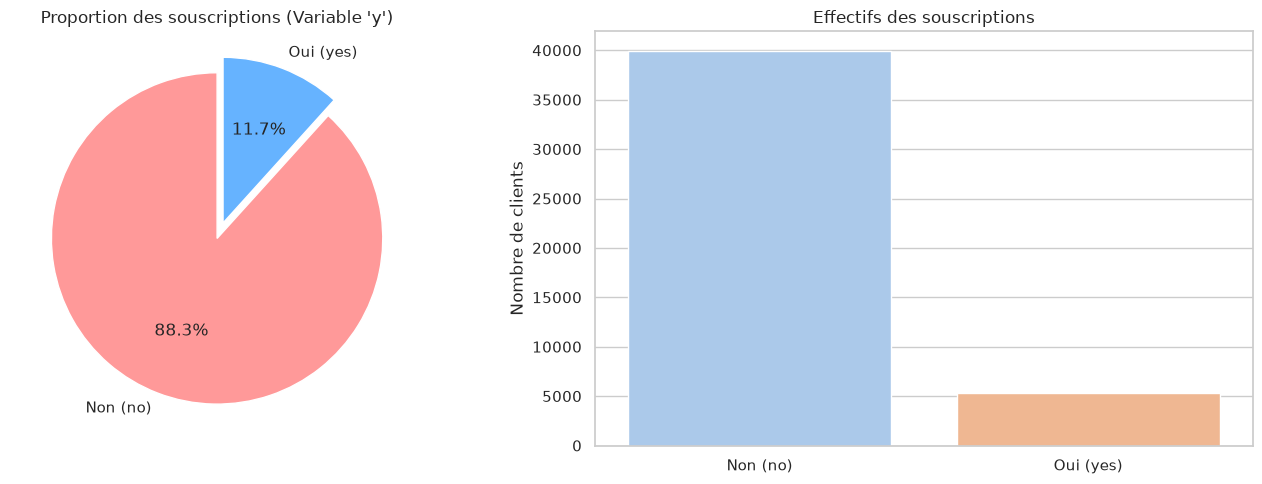

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration du style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Diagramme circulaire (Pie Chart)
colors = ['#ff9999','#66b3ff']
axes[0].pie(
    [totale_no, totale_yes],
    labels=['Non (no)', 'Oui (yes)'],
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    explode=(0, 0.1)
)
axes[0].set_title("Proportion des souscriptions (Variable 'y')")

# 2. Graphique en barres (Bar Plot)
sns.barplot(
    x=['Non (no)', 'Oui (yes)'],
    y=[totale_no, totale_yes],
    ax=axes[1],
    palette='pastel',
    hue=['Non (no)', 'Oui (yes)'],
    legend=False
)
axes[1].set_title("Effectifs des souscriptions")
axes[1].set_ylabel("Nombre de clients")

plt.tight_layout()
plt.show()

Cette répartition signifie qu'un modèle doit être évalué avec attention : une bonne exactitude ne garantit pas qu'il identifie efficacement les clients susceptibles de souscrire.

la cible est déséquilibrée.

Il sera notamment pertinent de regarder :
- Le rappel : quelle proportion des clients ayant souscrit est correctement identifiée ?
- La précision : parmi les clients prédits comme susceptibles de souscrire, quelle proportion a effectivement souscrit ?
- Le F1-score : quelle est la moyenne harmonique de la précision et du rappel ?



In [13]:
# Afficher les colonnes numériques
num_cols = df.select_dtypes(include="number").columns

print(num_cols)

Index(['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous'], dtype='str')


In [14]:
# Statistiques descriptives des variables numériques
df[num_cols].describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


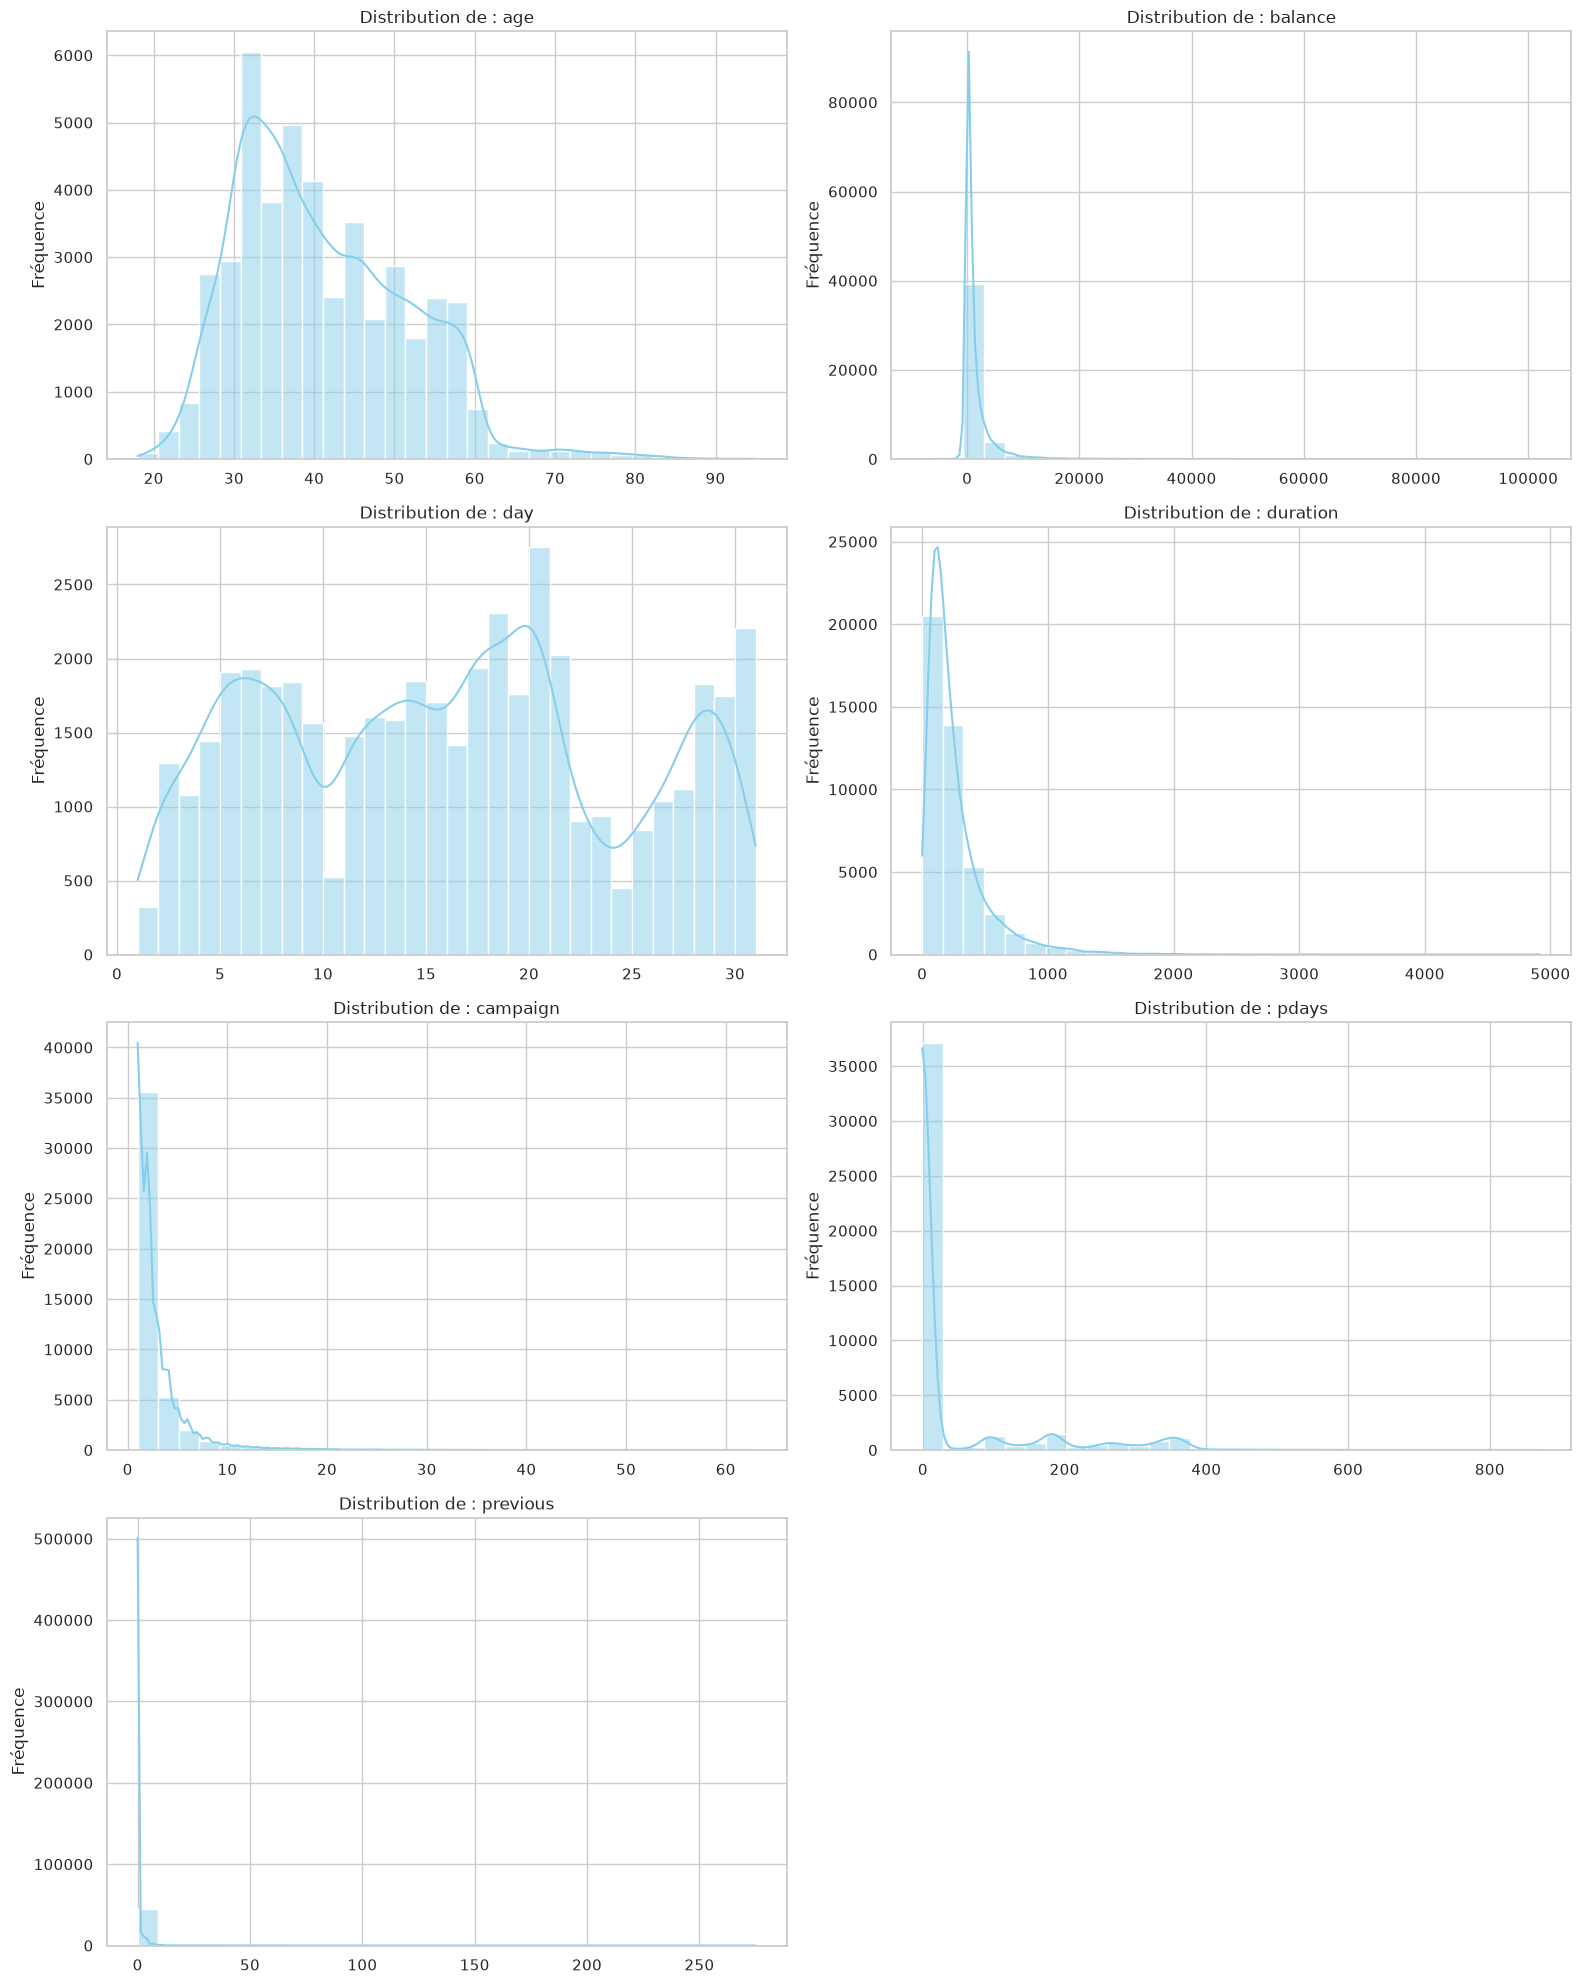

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration de la grille de graphiques
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(16, 20))
axes = axes.flatten()  # Pour aplatir la matrice d'axes en un tableau 1D

# Liste des variables numériques
num_cols = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

# Tracer un histogramme pour chaque variable numérique
for i, col in enumerate(num_cols):
    sns.histplot(df[col], ax=axes[i], kde=True, color='skyblue', bins=30)
    axes[i].set_title(f'Distribution de : {col}', fontsize=12)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Fréquence')

# Masquer le dernier sous-graphique qui est vide (car on a 7 variables pour 8 emplacements)
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

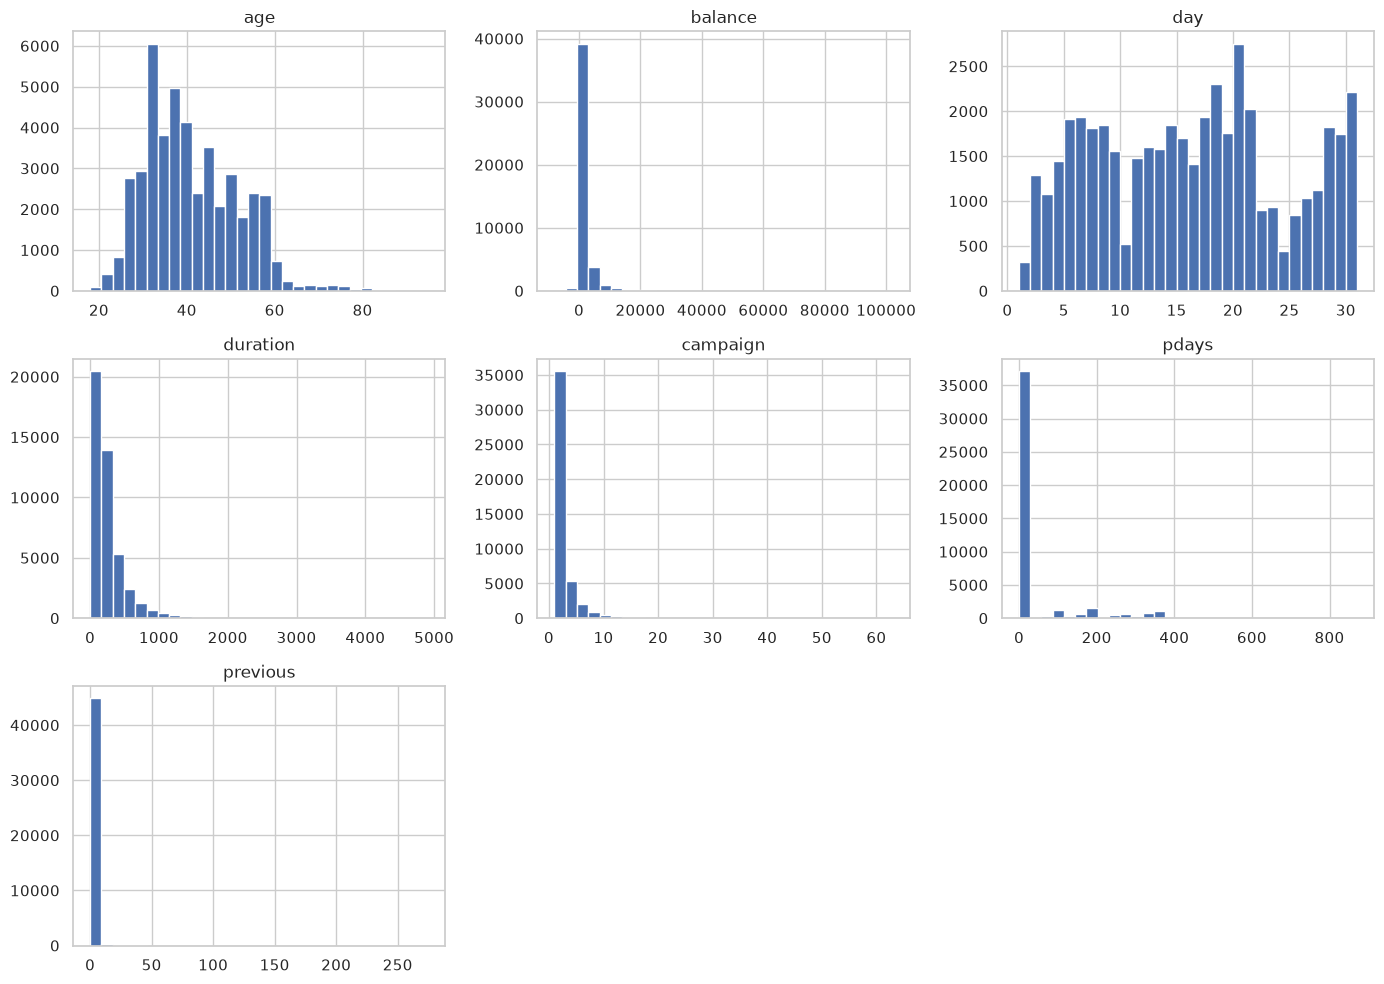

In [16]:
df[num_cols].hist(figsize=(14, 10), bins=30)

plt.tight_layout()
plt.show()

In [18]:
# Sélectionner les colonnes de type texte
cat_cols = df.select_dtypes(include="object").columns

print(cat_cols)

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome', 'y'],
      dtype='str')


/tmp/ipykernel_440529/3374018813.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns


In [19]:
print(df["job"].value_counts())

job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64


In [20]:
print(df["job"].value_counts(normalize=True) * 100)

job
blue-collar      21.525735
management       20.919688
technician       16.803433
admin.           11.437482
services          9.188029
retired           5.007631
self-employed     3.492513
entrepreneur      3.289023
unemployed        2.882042
housemaid         2.742695
student           2.074716
unknown           0.637013
Name: proportion, dtype: float64


In [21]:
for col in cat_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- job ---
job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64

--- marital ---
marital
married     27214
single      12790
divorced     5207
Name: count, dtype: int64

--- education ---
education
secondary    23202
tertiary     13301
primary       6851
unknown       1857
Name: count, dtype: int64

--- default ---
default
no     44396
yes      815
Name: count, dtype: int64

--- housing ---
housing
yes    25130
no     20081
Name: count, dtype: int64

--- loan ---
loan
no     37967
yes     7244
Name: count, dtype: int64

--- contact ---
contact
cellular     29285
unknown      13020
telephone     2906
Name: count, dtype: int64

--- month ---
month
may    13766
jul     6895
aug     6247
jun     5341
nov     3970
apr     2932
feb     2649
jan     1403

In [22]:
taux_souscription = pd.crosstab(
    df["job"],
    df["y"],
    normalize="index"
) * 100

print(taux_souscription)

y                     no        yes
job                                
admin.         87.797331  12.202669
blue-collar    92.725031   7.274969
entrepreneur   91.728312   8.271688
housemaid      91.209677   8.790323
management     86.244449  13.755551
retired        77.208481  22.791519
self-employed  88.157061  11.842939
services       91.116996   8.883004
student        71.321962  28.678038
technician     88.943004  11.056996
unemployed     84.497314  15.502686
unknown        88.194444  11.805556


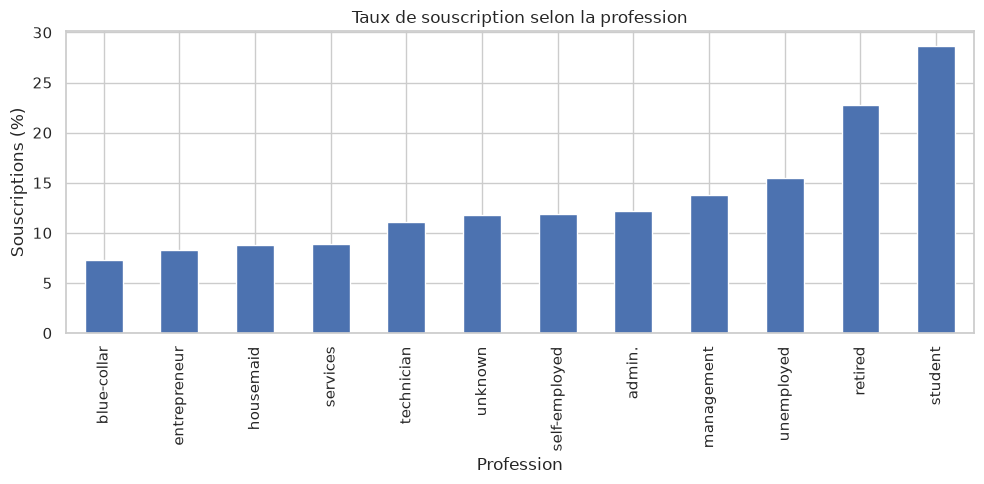

In [23]:
taux_souscription["yes"].sort_values().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Taux de souscription selon la profession")
plt.xlabel("Profession")
plt.ylabel("Souscriptions (%)")
plt.tight_layout()

plt.show()

#  Quelles variables nécessitent un encodage ?


Les modèles d'apprentissage automatique ont généralement besoin de variables numériques en entrée.
Les variables catégorielles comme job, marital ou education doivent donc être converties en représentation numérique.

# 1. One-Hot Encoding
Cette méthode crée une colonne par catégorie.
Par exemple, la variable marital peut être transformée en trois colonnes :


| marital | marital_divorced | marital_married | marital_single |
|---:|---:|---:|---:|
| divorced | 1 | 0 | 0 |
| married | 0 | 1 | 0 |
| single | 0 | 0 | 1 |




# 2. Label Encoding

Cette méthode associe un nombre à chaque catégorie.

Attention : attribuer des nombres à des catégories sans ordre naturel peut donner l'impression qu'elles ont une relation numérique qui n'existe pas.
Pour un premier modèle, le One-Hot Encoding est souvent un choix adapté aux variables nominales.



Taux de souscription selon job
y                 no    yes
job                        
admin.         87.80  12.20
blue-collar    92.73   7.27
entrepreneur   91.73   8.27
housemaid      91.21   8.79
management     86.24  13.76
retired        77.21  22.79
self-employed  88.16  11.84
services       91.12   8.88
student        71.32  28.68
technician     88.94  11.06
unemployed     84.50  15.50
unknown        88.19  11.81


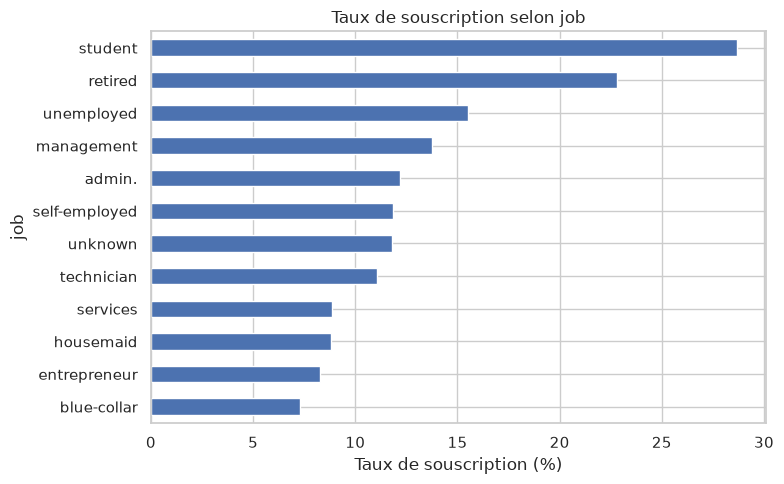


Taux de souscription selon education
y             no    yes
education              
primary    91.37   8.63
secondary  89.44  10.56
tertiary   84.99  15.01
unknown    86.43  13.57


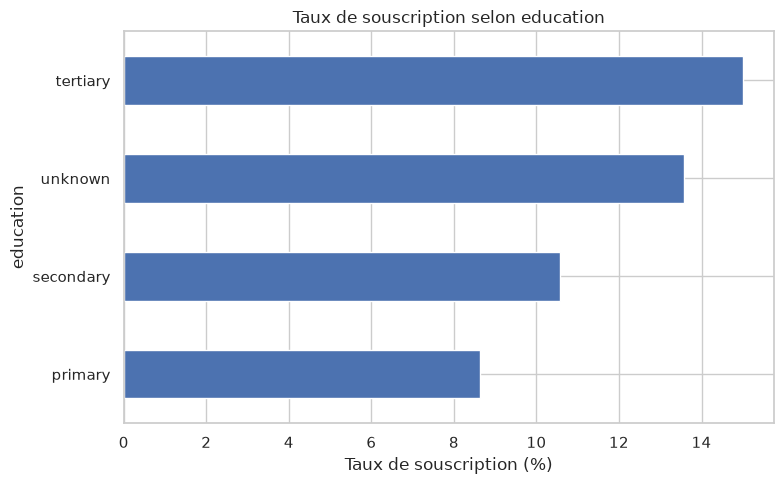


Taux de souscription selon marital
y            no    yes
marital               
divorced  88.05  11.95
married   89.88  10.12
single    85.05  14.95


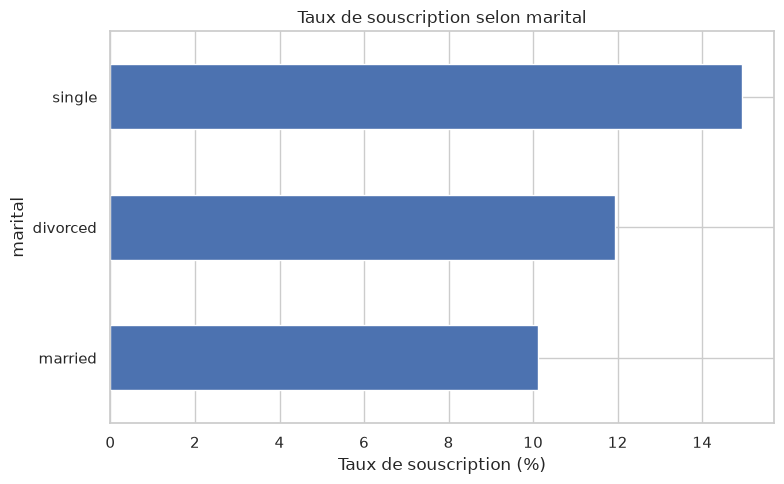


Taux de souscription selon housing
y          no   yes
housing            
no       83.3  16.7
yes      92.3   7.7


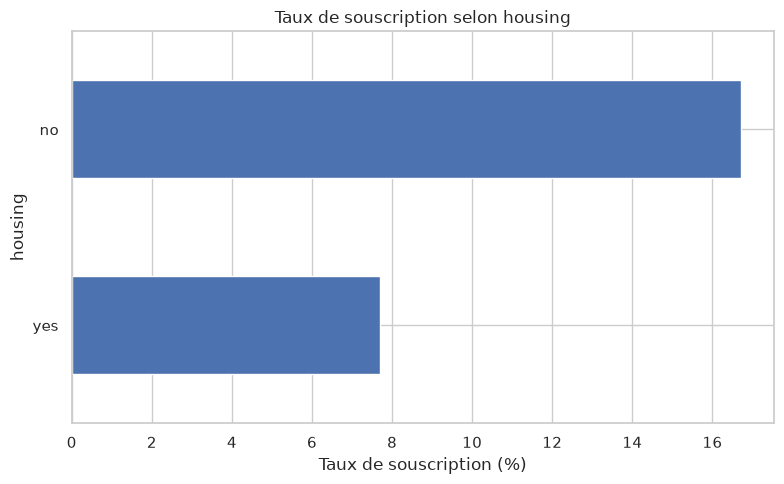


Taux de souscription selon contact
y             no    yes
contact                
cellular   85.08  14.92
telephone  86.58  13.42
unknown    95.93   4.07


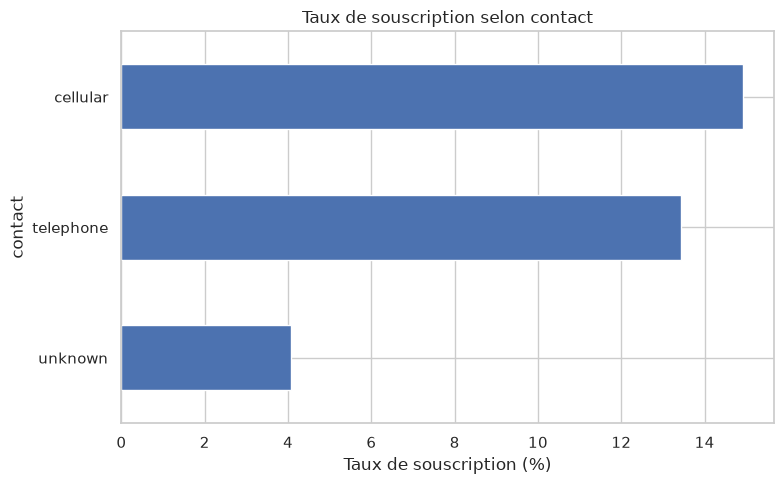

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Variables catégorielles à analyser
variables_cat = [
    "job",
    "education",
    "marital",
    "housing",
    "contact"
]

# Calcul du taux de souscription par catégorie
for col in variables_cat:

    taux = pd.crosstab(
        df[col],
        df["y"],
        normalize="index"
    ) * 100

    print(f"\nTaux de souscription selon {col}")
    print(taux.round(2))

    # Visualisation
    taux["yes"].sort_values().plot(
        kind="barh",
        figsize=(8, 5)
    )

    plt.title(f"Taux de souscription selon {col}")
    plt.xlabel("Taux de souscription (%)")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

un taux plus élevé ne signifie pas nécessairement que la catégorie représente le plus grand nombre de souscriptions.

Il faut aussi regarder le nombre de clients dans chaque groupe.


In [25]:
resultats = (
    df.groupby("job", observed=True)
      .agg(
          nombre_clients=("y", "size"),
          souscriptions=("y", lambda x: (x == "yes").sum())
      )
)

resultats["taux_souscription"] = (
    resultats["souscriptions"]
    / resultats["nombre_clients"]
    * 100
)

print(
    resultats.sort_values(
        "taux_souscription",
        ascending=False
    ).round(2)
)

               nombre_clients  souscriptions  taux_souscription
job                                                            
student                   938            269              28.68
retired                  2264            516              22.79
unemployed               1303            202              15.50
management               9458           1301              13.76
admin.                   5171            631              12.20
self-employed            1579            187              11.84
unknown                   288             34              11.81
technician               7597            840              11.06
services                 4154            369               8.88
housemaid                1240            109               8.79
entrepreneur             1487            123               8.27
blue-collar              9732            708               7.27


# Test du Khi-deux : variables catégorielles
Le test du Khi-deux d'indépendance permet d'étudier l'association entre deux variables catégorielles.

In [27]:
%pip install scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 17.3 MB/s  0:00:02 eta 0:00:010:01:01
Note: you may need to restart the kernel to use updated packages.


In [28]:
from scipy.stats import chi2_contingency

variables_cat = [
    "job",
    "education",
    "marital",
    "housing",
    "contact",
    "month",
    "poutcome"
]

for col in variables_cat:

    tableau = pd.crosstab(df[col], df["y"])

    chi2, p_value, ddl, effectifs_attendus = (
        chi2_contingency(tableau)
    )

    print(f"\nVariable : {col}")
    print(f"Statistique Khi-deux : {chi2:.2f}")
    print(f"Degrés de liberté : {ddl}")
    print(f"P-value : {p_value:.6f}")


Variable : job
Statistique Khi-deux : 836.11
Degrés de liberté : 11
P-value : 0.000000

Variable : education
Statistique Khi-deux : 238.92
Degrés de liberté : 3
P-value : 0.000000

Variable : marital
Statistique Khi-deux : 196.50
Degrés de liberté : 2
P-value : 0.000000

Variable : housing
Statistique Khi-deux : 874.82
Degrés de liberté : 1
P-value : 0.000000

Variable : contact
Statistique Khi-deux : 1035.71
Degrés de liberté : 2
P-value : 0.000000

Variable : month
Statistique Khi-deux : 3061.84
Degrés de liberté : 11
P-value : 0.000000

Variable : poutcome
Statistique Khi-deux : 4391.51
Degrés de liberté : 3
P-value : 0.000000


Si p-value < 0,05 : les données fournissent des éléments contre l'hypothèse d'indépendance entre les variables.
Si p-value ≥ 0,05 : on ne dispose pas de suffisamment d'éléments pour rejeter cette hypothèse.

 Toutes ces variables sont fortement associées de manière statistiquement significative à la décision de souscription d'un client. Elles sont donc toutes d'excellentes candidates à inclure comme caractéristiques (features) pour entraîner votre futur modèle de Machine Learning.

poutcome (Résultat de la campagne précédente) - Khi-deux : 4391.51

    C'est la statistique de test la plus élevée de toutes.
    Interprétation : Le fait qu'un client ait déjà souscrit avec succès (success) lors de la campagne précédente est le facteur d'association le plus puissant avec une nouvelle souscription.

month (Dernier mois de contact) - Khi-deux : 3061.84

    Très forte association.
    Interprétation : Le moment de l'année où le client est contacté a un impact majeur (par exemple, certains mois comme mars, septembre ou octobre affichent des taux de réussite bien plus élevés que la moyenne).

contact (Moyen de communication) - Khi-deux : 1035.71

    Interprétation : Le canal utilisé (par exemple, le téléphone portable par rapport à un téléphone fixe ou un canal inconnu) montre des différences d'efficacité très nettes.

housing (Prêt immobilier en cours) - Khi-deux : 874.82

    Interprétation : Avoir déjà un emprunt immobilier à rembourser diminue significativement la propension d'un client à bloquer de l'argent dans un dépôt à terme.

job (Profession) - Khi-deux : 836.11

    Interprétation : Comme observé précédemment, certaines catégories professionnelles (étudiants, retraités) sont beaucoup plus enclines à souscrire que d'autres (ouvriers/blue-collar).

education (Niveau d'études) & marital (Statut marital) - Khi-deux : 238.92 & 196.50

    Bien que leurs statistiques de Khi-deux soient plus faibles que pour les autres variables, elles restent hautement significatives (P-value = 0).
    Interprétation : Les clients célibataires ou ayant fait des études supérieures (tertiary) ont un comportement de souscription statistiquement différent des couples mariés ou des personnes ayant un niveau d'études primaires.

# Mesurer la force de l'association avec le V de Cramér

Le V de Cramér varie entre 0 et 1 :
- Une valeur proche de 0 indique une association faible.
- Une valeur plus élevée indique une association plus forte.
Il n'existe toutefois pas de seuil universel permettant de qualifier automatiquement une association de faible, moyenne ou forte : le contexte compte.

In [29]:
import numpy as np
from scipy.stats import chi2_contingency

def cramers_v(tableau):
    chi2 = chi2_contingency(tableau)[0]

    n = tableau.to_numpy().sum()
    lignes, colonnes = tableau.shape

    denominateur = n * min(lignes - 1, colonnes - 1)

    if denominateur == 0:
        return np.nan

    return np.sqrt(chi2 / denominateur)


for col in variables_cat:

    tableau = pd.crosstab(df[col], df["y"])

    print(
        col,
        round(cramers_v(tableau), 3)
    )

job 0.136
education 0.073
marital 0.066
housing 0.139
contact 0.151
month 0.26
poutcome 0.312


# 3. Analyser les variables numériques selon la souscription

permet de déterminer si les clients ayant souscrit présentent des caractéristiques numériques différentes des autres clients.


Les clients ayant souscrit ont-ils un âge différent ?
Leur solde bancaire moyen est-il plus élevé ?
Le nombre de contacts diffère-t-il selon le résultat ?
La durée du dernier appel est-elle associée à la souscription ?



In [30]:
variables_num = [
    "age",
    "balance",
    "day",
    "duration",
    "campaign",
    "pdays",
    "previous"
]

resume = df.groupby("y")[variables_num].agg(
    ["mean", "median", "std"]
)

print(resume.round(2))

       age                balance                   day              duration  \
      mean median    std     mean median     std   mean median   std     mean   
y                                                                               
no   40.84   39.0  10.17  1303.71  417.0  2974.2  15.89   16.0  8.29   221.18   
yes  41.67   38.0  13.50  1804.27  733.0  3501.1  15.16   15.0  8.50   537.29   

     ...         campaign               pdays                previous         \
     ...     std     mean median   std   mean median     std     mean median   
y    ...                                                                       
no   ...  207.38     2.85    2.0  3.21  36.42   -1.0   96.76     0.50    0.0   
yes  ...  392.53     2.14    2.0  1.92  68.70   -1.0  118.82     1.17    0.0   

           
      std  
y          
no   2.26  
yes  2.55  

[2 rows x 21 columns]


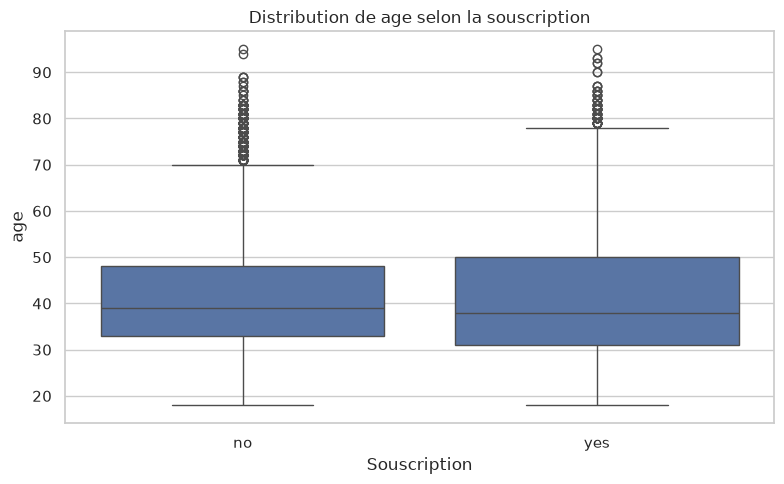

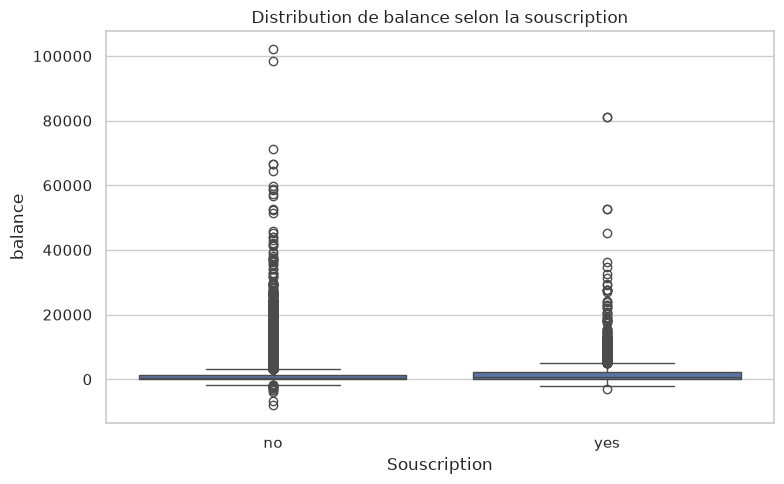

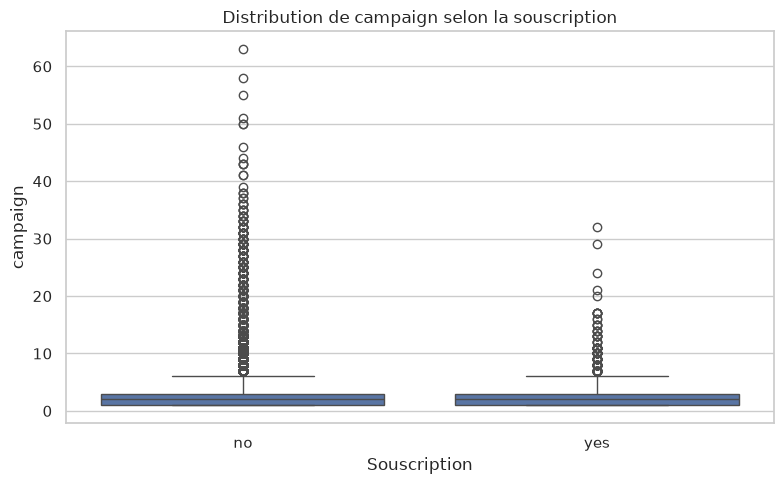

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

variables_a_visualiser = [
    "age",
    "balance",
    "campaign",

]

for col in variables_a_visualiser:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x="y",
        y=col
    )

    plt.title(f"Distribution de {col} selon la souscription")
    plt.xlabel("Souscription")
    plt.ylabel(col)

    plt.tight_layout()
    plt.show()

Si les deux distributions se ressemblent beaucoup, la variable peut avoir un pouvoir discriminant limité lorsqu'elle est utilisée seule.
Cependant, une variable peu discriminante isolément peut rester utile lorsqu'elle est combinée à d'autres variables dans un modèle.

Pour vérifier si les différences observées entre les clients ayant souscrit et les autres sont statistiquement significatives, tu peux utiliser des tests adaptés à la distribution des données.


#A. Le test de Mann-Whitney
Ce test non paramétrique permet de comparer les distributions de deux groupes indépendants.
Il est particulièrement intéressant pour des variables comme balance ou campaign, dont les distributions peuvent être asymétriques.

In [32]:
from scipy.stats import mannwhitneyu

variables_num = [
    "age",
    "balance",
    "campaign",
    "duration"
]

for col in variables_num:

    groupe_no = df.loc[df["y"] == "no", col].dropna()
    groupe_yes = df.loc[df["y"] == "yes", col].dropna()

    statistique, p_value = mannwhitneyu(
        groupe_no,
        groupe_yes,
        alternative="two-sided"
    )

    print(f"\nVariable : {col}")
    print(f"P-value : {p_value:.6g}")


Variable : age
P-value : 0.0628179

Variable : balance
P-value : 6.59385e-101

Variable : campaign
P-value : 1.94849e-71

Variable : duration
P-value : 0


Une p-value inférieure à 0,05 indique une différence statistiquement détectable entre les distributions, sous les hypothèses du test.
Une p-value supérieure ou égale à 0,05 ne permet pas de conclure à une différence statistiquement détectable.

Si tu réalises de nombreux tests statistiques, certaines p-values peuvent être inférieures à 0,05 simplement par hasard.
Tu peux appliquer une correction de Holm pour limiter le risque de faux positifs.


In [34]:
%pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 21.6 MB/s  0:00:0022.4 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [statsmodels] 5/6 [statsmodels]laic]
Note: you may need to restart the kernel to use updated packages.


In [35]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

p_values = []

for col in variables_num:

    groupe_no = df.loc[df["y"] == "no", col].dropna()
    groupe_yes = df.loc[df["y"] == "yes", col].dropna()

    _, p_value = mannwhitneyu(
        groupe_no,
        groupe_yes,
        alternative="two-sided"
    )

    p_values.append(p_value)

rejet, p_values_corrigees, _, _ = multipletests(
    p_values,
    alpha=0.05,
    method="holm"
)

for col, p_corrigee, significatif in zip(
    variables_num,
    p_values_corrigees,
    rejet
):
    print(
        f"{col} : p-value corrigée = {p_corrigee:.6g}, "
        f"significatif = {significatif}"
    )

age : p-value corrigée = 0.0628179, significatif = False
balance : p-value corrigée = 1.97815e-100, significatif = True
campaign : p-value corrigée = 3.89698e-71, significatif = True
duration : p-value corrigée = 0, significatif = True


Cette correction est utile lorsque tu compares plusieurs variables simultanément.


#les corrélations entre variables numériques

La corrélation permet de mesurer l'intensité et le sens d'une relation statistique entre deux variables numériques.
Par exemple :
- L'âge est-il associé au solde bancaire ?
- Le nombre de contacts est-il associé à la durée des appels ?
- Certaines variables contiennent-elles des informations redondantes ?

| Valeur | Interprétation générale |
|---|---|
| Proche de +1 | Association monotone croissante forte |
| Proche de 0 | Absence d'association monotone marquée |
| Proche de -1 | Association monotone décroissante forte |

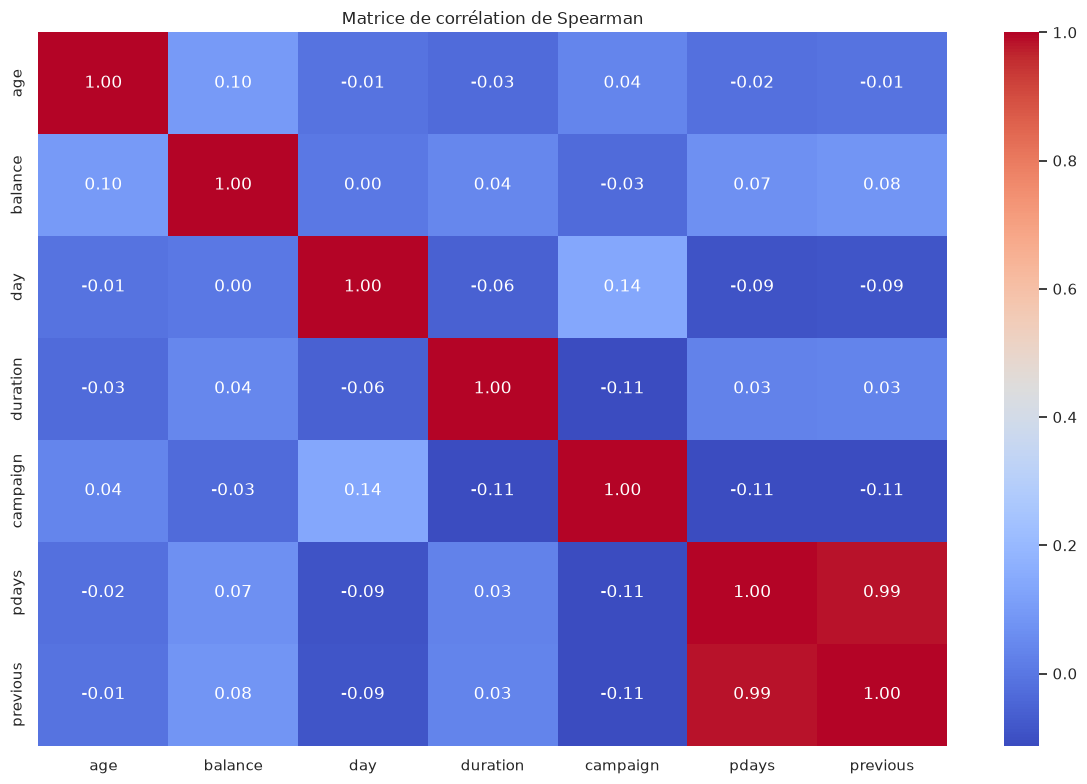

In [36]:

variables_num = df.select_dtypes(include="number")

correlation = variables_num.corr(method="spearman")

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matrice de corrélation de Spearman")

plt.tight_layout()
plt.show()


une corrélation ne démontre pas un lien de causalité.


# Analyser les variables en fonction de leur utilité métier

La banque ne cherche pas seulement à savoir quelles variables sont associées à la souscription. Elle veut identifier les clients auxquels il serait pertinent de consacrer du temps lors des prochaines campagnes.
Il est donc utile de comparer les taux de souscription en fonction de variables opérationnelles.



month
mar    51.99
dec    46.73
sep    46.46
oct    43.77
apr    19.68
feb    16.65
aug    11.01
jun    10.22
nov    10.15
jan    10.12
jul     9.09
may     6.72
Name: y, dtype: float64


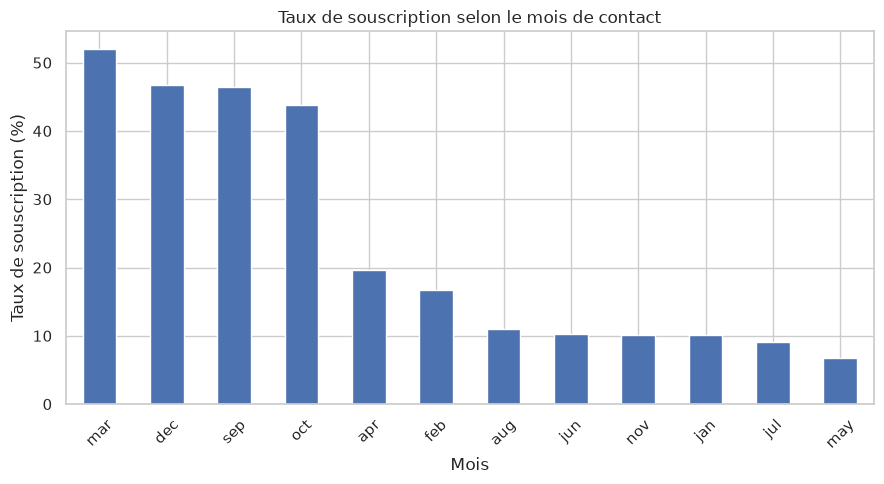

In [37]:
taux_mois = (
    df.groupby("month", observed=True)["y"]
      .apply(lambda x: (x == "yes").mean() * 100)
      .sort_values(ascending=False)
)

print(taux_mois.round(2))

taux_mois.plot(kind="bar", figsize=(9, 5))

plt.title("Taux de souscription selon le mois de contact")
plt.xlabel("Mois")
plt.ylabel("Taux de souscription (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [38]:
taux_contacts = (
    df.groupby("campaign", observed=True)["y"]
      .apply(lambda x: (x == "yes").mean() * 100)
)

print(taux_contacts.sort_index().round(2))

campaign
1     14.60
2     11.20
3     11.19
4      9.00
5      7.88
6      7.13
7      6.39
8      5.93
9      6.42
10     5.26
11     7.96
12     2.58
13     4.51
14     4.30
15     4.76
16     2.53
17     8.70
18     0.00
19     0.00
20     2.33
21     2.86
22     0.00
23     0.00
24     5.00
25     0.00
26     0.00
27     0.00
28     0.00
29     6.25
30     0.00
31     0.00
32    11.11
33     0.00
34     0.00
35     0.00
36     0.00
37     0.00
38     0.00
39     0.00
41     0.00
43     0.00
44     0.00
46     0.00
50     0.00
51     0.00
55     0.00
58     0.00
63     0.00
Name: y, dtype: float64


| Priorité | Analyse | Intérêt |
|---|---|---|
| Indispensable | Valeurs manquantes et `unknown` | Évaluer la qualité des données |
| Indispensable | Distribution de la cible | Comprendre le déséquilibre des classes |
| Indispensable | Statistiques descriptives numériques | Comprendre les distributions |
| Élevée | Taux de souscription par catégorie | Identifier les associations métier |
| Élevée | Boîtes à moustaches par classe | Comparer les distributions numériques |
| Élevée | Test du Khi-deux et V de Cramér | Mesurer les associations catégorielles |
| Élevée | Test de Mann-Whitney | Comparer les distributions numériques |
| Moyenne | Matrice de corrélation | Repérer les relations entre variables |
| Moyenne | Analyse du mois et du nombre de contacts | Comprendre les résultats des campagnes |
| Pour la suite | Régression logistique | Étudier plusieurs variables simultanément |

### Conclusion sur la qualité des données

L'exploration du jeu de données Bank Marketing permet de comprendre sa structure, la nature des variables et les éventuelles anomalies présentes.

La première étape consiste à vérifier le nombre d'observations, le nombre de variables, les types de données et la présence de valeurs manquantes.

Une attention particulière doit être portée aux valeurs `unknown`, présentes dans certaines variables catégorielles. Elles correspondent à des informations inconnues ou non renseignées et ne doivent pas être automatiquement assimilées à des valeurs manquantes classiques.

Il convient également d'examiner les valeurs particulières des variables numériques, notamment celles qui correspondent à des conventions de codage plutôt qu'à des mesures réelles.

Cette analyse préliminaire est essentielle pour déterminer les traitements nécessaires avant la construction d'un modèle prédictif.

### Analyse de la distribution de la cible

La variable cible `y` indique si un client a souscrit à un dépôt à terme (`yes`) ou n'a pas souscrit (`no`).

La distribution des classes est déséquilibrée : la classe `no` est largement majoritaire, tandis que la classe `yes` représente une minorité des observations.

Cette répartition constitue un point important pour la suite du projet. En effet, un modèle pourrait obtenir une exactitude élevée en prédisant principalement la classe majoritaire, sans parvenir à identifier correctement les clients qui souscrivent.

Il sera donc nécessaire d'évaluer les futurs modèles à l'aide de plusieurs indicateurs, notamment la précision, le rappel, le F1-score et la matrice de confusion.

Dans le contexte métier, le rappel de la classe `yes` permettra notamment d'évaluer la capacité du modèle à identifier les clients qui souscrivent effectivement. La précision permettra de mesurer la proportion de souscriptions réelles parmi les clients prédits comme susceptibles de souscrire.

Le choix du modèle devra également tenir compte du coût des appels, du temps consacré aux clients et du risque de manquer une souscription potentielle.

### Analyse des variables catégorielles

L'analyse des taux de souscription selon les catégories permet d'identifier des différences de comportement entre les groupes de clients.

Les variables `job`, `education`, `marital`, `housing`, `loan`, `contact`, `month` et `poutcome` ont été étudiées afin de déterminer si les taux de souscription varient selon les catégories observées.

Les tableaux croisés permettent de comparer les proportions de souscription, tandis que le test du Khi-deux permet d'évaluer l'existence d'une association statistique entre chaque variable catégorielle et la cible.

Le V de Cramér complète cette analyse en mesurant la force de l'association.

Les variables présentant des différences de taux de souscription importantes et des associations statistiquement étayées pourront être examinées plus en détail lors de la modélisation.

Toutefois, une association statistique ne démontre pas une relation de causalité et ne garantit pas, à elle seule, une bonne capacité prédictive.

### Analyse des variables numériques

L'analyse descriptive des variables numériques permet d'étudier les différences de distribution entre les clients ayant souscrit et ceux n'ayant pas souscrit.

Les moyennes, les médianes, les écarts-types et les graphiques permettent notamment de repérer les distributions asymétriques, les valeurs extrêmes et les éventuelles différences entre les deux groupes.

Les tests statistiques peuvent ensuite aider à déterminer si certaines différences de distribution sont statistiquement significatives.

Une différence statistique doit cependant être interprétée en tenant compte de sa magnitude, de la taille des groupes et du contexte métier.

Enfin, toutes les variables numériques ne sont pas nécessairement adaptées à un modèle utilisé avant la campagne. En particulier, la durée du dernier appel (`duration`) n'est connue qu'après l'appel et ne doit donc généralement pas être utilisée pour cibler les clients avant leur contact.


### Analyse des valeurs particulières

L'exploration met en évidence la nécessité de distinguer les valeurs manquantes classiques des valeurs spéciales utilisées pour coder certaines informations.

Les modalités `unknown` présentes dans les variables catégorielles correspondent à des informations inconnues et doivent être examinées avant de décider d'un éventuel traitement.

La variable `pdays` nécessite une attention particulière : dans la version historique du dataset, la valeur 999 sert généralement à indiquer l'absence de contact lors d'une campagne précédente. Elle ne représente donc pas une durée réelle de 999 jours.

Ces conventions de codage doivent être prises en compte lors de l'analyse statistique et de la préparation des données. Les valeurs particulières ne doivent pas être supprimées ou remplacées sans justification, car elles peuvent contenir une information utile à la modélisation.

### Conclusion générale et implications métier

L'exploration du dataset Bank Marketing constitue une première étape essentielle pour comprendre les caractéristiques des clients et les résultats des campagnes de prospection.

La distribution déséquilibrée de la cible montre que la souscription reste minoritaire dans les données historiques. La construction d'un modèle devra donc privilégier une évaluation adaptée à cet objectif, plutôt que de se limiter à l'exactitude globale.

L'analyse des variables catégorielles et numériques permettra de repérer les caractéristiques associées à des taux de souscription différents. Ces résultats serviront à formuler des hypothèses et à sélectionner les variables à examiner lors de la modélisation.

Les valeurs particulières, notamment `unknown` et la convention de codage de `pdays`, devront être traitées avec précaution afin d'éviter des interprétations erronées.

La prochaine étape consistera à préparer les données, à séparer les données d'entraînement et de test, puis à construire et comparer plusieurs modèles de classification.

L'objectif final sera d'identifier les clients présentant une probabilité élevée de souscription, en tenant compte des coûts de prospection et des informations réellement disponibles au moment de la décision.

| Variable | Analyse effectuée | Résultat à renseigner | Interprétation métier |
|---|---|---|---|
| `y` | Distribution des classes | Pourcentage de `yes` et `no` | Évaluer le déséquilibre |
| `job` | Taux par catégorie et Khi-deux | P-value et V de Cramér | Examiner les différences entre professions |
| `education` | Taux par catégorie et Khi-deux | P-value et V de Cramér | Étudier les différences selon le niveau d'éducation |
| `balance` | Comparaison des distributions | Médianes et p-value | Examiner les différences de soldes |
| `age` | Comparaison des distributions | Médianes et p-value | Étudier les différences d'âge |
| `campaign` | Comparaison des distributions | Médianes et p-value | Examiner les liens entre répétition des appels et souscription |
| `month` | Taux par catégorie | Taux de souscription mensuels | Étudier les variations entre périodes |
| `poutcome` | Taux par catégorie | Taux de souscription et effectifs | Examiner les liens avec les résultats précédents |